**ANOMALY DETECTION COSINE SIMILARITY**

In [3]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [16]:
job_name = "net_v3_10per"                                    
dataset_standard = "Standard" 
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v3"

parameters = {
    "job_name": job_name,                         # job_name del TRAINING MoCo da valutare
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         # split della cache Floods_Anomalies_{split}_crop_norm
    "moco_version": moco_version,   
    "simple_proj": False,                           # questi 6 devono essere identici a quelli del training,
    "attn": False,                                  # altrimenti load_state_dict fallisce per shape diverse
    "hidden_channels_dim": 64,
    "pool_grid": 4,
    
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico
    "n_normal_eval": 1085,
    "num_anomalies": 1085,
    "n_threshold_series": 0,             
    "n_std": 1.0,                           
    "batch_size": 16,
    "workers": 0,       
    "min_flood_pct": 20.0                     
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",      
        "spec": {"size": "500Gi"}   
    }
]

**BUILD ENVIRONMENT**

In [7]:
ad_train_func = project.new_function(
    name= f'ad_cosine_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/", 
    handler="anomaly:ad_cosine", 
    base_image="pytorch/pytorch:2.1.2-cuda11.8-cudnn8-runtime",
    requirements=["pandas==2.3.3", "numpy==1.26.4", "rasterio==1.4.4", "tqdm==4.70.0", "tifffile==2024.8.30", "torch==2.1.2", "matplotlib==3.10.9", "digitalhub==0.15.11", "digitalhub-runtime-python==0.15.2", "zarr==2.18.0", "numcodecs==0.13.1", "xarray==2025.6.1"]
)

build = ad_train_func.run("build", wait=True)
print(f"BUILD: {build.status.state}")

2026-10-09 14:59:19,805 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dda8f33a3a554c41ac128f950523efab to finish...
2026-10-09 14:59:24,913 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dda8f33a3a554c41ac128f950523efab to finish...
2026-10-09 14:59:29,920 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dda8f33a3a554c41ac128f950523efab to finish...
2026-10-09 14:59:34,927 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dda8f33a3a554c41ac128f950523efab to finish...
2026-10-09 14:59:39,934 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dda8f33a3a554c41ac128f950523efab to finish...
2026-10-09 14:59:44,942 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dda8f33a3a554c41ac128f950523efab to finish...
2026-10-09 14:59:49,950 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dda8f33a3a554c41ac128f950523efab to finish...
2026-10-09 14

BUILD: COMPLETED


**TRAINING**

In [8]:
run_ad = ad_train_func.run(
    action="job", 
    parameters=parameters, 
    volumes=volumes, 
    profile="1xv100-shared",                                       
    local_execution= False,                                
    wait=True
)

print(f"Run train_encoders avviato: {run_ad.id}")

2026-10-09 15:02:21,083 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run fa797a0c1b3f4d05b9e05569385a5e6d to finish...


2026-10-09 15:02:26,090 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run fa797a0c1b3f4d05b9e05569385a5e6d to finish...
2026-10-09 15:02:31,098 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run fa797a0c1b3f4d05b9e05569385a5e6d to finish...
2026-10-09 15:02:36,106 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run fa797a0c1b3f4d05b9e05569385a5e6d to finish...
2026-10-09 15:02:41,113 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run fa797a0c1b3f4d05b9e05569385a5e6d to finish...
2026-10-09 15:02:46,121 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run fa797a0c1b3f4d05b9e05569385a5e6d to finish...
2026-10-09 15:02:51,131 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run fa797a0c1b3f4d05b9e05569385a5e6d to finish...
2026-10-09 15:02:56,242 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run fa797a0c1b3f4d05b9e05569385a5e6d to finish...
2026-10-09 15

Run train_encoders avviato: fa797a0c1b3f4d05b9e05569385a5e6d


In [17]:
zip_path = project.get_artifact(f"anomaly_results_{job_name}").download("/tmp/anomaly_results.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall("/tmp/anomaly_results")

In [18]:
with open("/tmp/anomaly_results/anomaly_results.json") as f:
    results = json.load(f)

print(f"n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"thr: media {results['thr']['mean']:.4f} ± {results['thr']['std']:.4f} -> [{results['thr']['thr_low']:.4f}, {results['thr']['thr_high']:.4f}]")
print(f"cos_sim normali: {results['cos_sim_normal']['mean']:.4f} ± {results['cos_sim_normal']['std']:.4f}")
print(f"cos_sim anomale: {results['cos_sim_anom']['mean']:.4f} ± {results['cos_sim_anom']['std']:.4f}", "\n")
print(f"AUROC (similarità alta = anomalia): {results['auroc_cos_sim_high_anom']:.3f}")
print(f"AUROC (similarità bassa = anomalia): {results['auroc_cos_sim_low_anom']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

n_thr: 3397 | n_normali: 1577 | n_anomale: 1577 

thr: media 0.3578 ± 0.1302 -> [0.2276, 0.4880]
cos_sim normali: 0.3626 ± 0.1312
cos_sim anomale: 0.3318 ± 0.1480 

AUROC (similarità alta = anomalia): 0.441
AUROC (similarità bassa = anomalia): 0.559


,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
cos_sim > m+1*std,229.0,269.0,1348.0,1308.0,0.170577,0.854788,0.145212,0.459839,0.220723
cos_sim < m-1*std,396.0,227.0,1181.0,1350.0,0.143944,0.748890,0.251110,0.635634,0.360000
m-1*std < cos_sim < m+1*std,625.0,496.0,952.0,1081.0,0.314521,0.603678,0.396322,0.557538,0.463306


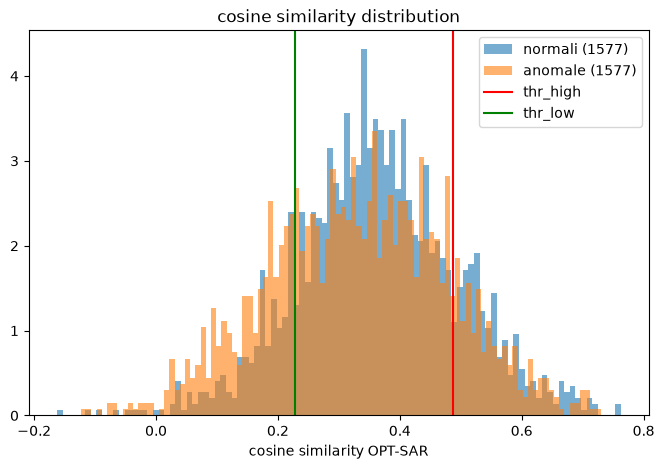

In [19]:
df = pd.read_csv("/tmp/anomaly_results/similarities.csv")
cos_sim_normal = df[df.label == 0]['similarity']
cos_sim_anom = df[df.label == 1]['similarity']

with open("/tmp/anomaly_results/anomaly_results.json") as f:
    results = json.load(f)
thr_high = results['thr']['thr_high']
thr_low = results['thr']['thr_low']

plt.figure(figsize=(8, 5))
plt.hist(cos_sim_normal, bins=100, alpha=0.6, density=True, label=f"normali ({len(cos_sim_normal)})")
plt.hist(cos_sim_anom, bins=100, alpha=0.6, density=True, label=f"anomale ({len(cos_sim_anom)})")
plt.axvline(x=thr_high, color='r', label='thr_high')
plt.axvline(x=thr_low, color='g', label='thr_low')
plt.xlabel("cosine similarity OPT-SAR")
plt.legend()
plt.title(f"cosine similarity distribution")
plt.show()

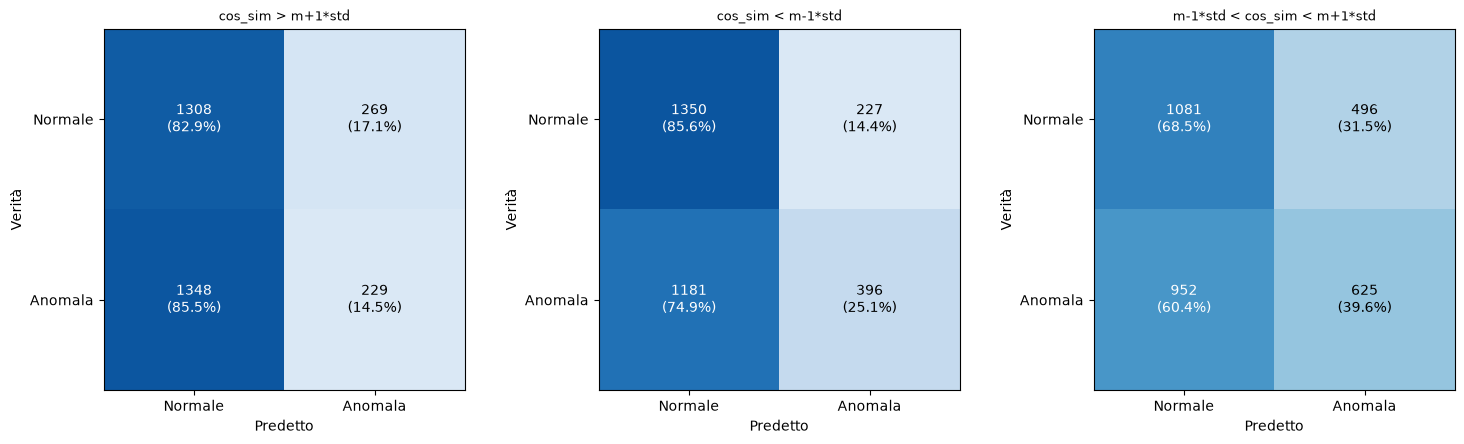

In [20]:
rules = results['rules']   
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5))

for ax, (nome, r) in zip(axes, rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100   

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

plt.tight_layout()
plt.show()